In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# 1. 現在のフォルダ(my_new_project)の1つ上(..)に行き、
# さらにモジュールが入っているフォルダ(nafusion_utils)まで確実におさえる
base_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "nafusion_utils"))

if base_dir not in sys.path:
    sys.path.append(base_dir)


import magcalc

# 以下3行、使わないならコメントアウト
import nafusion_utils as nf
nf.set_style()
%matplotlib widget

# NUMBER の磁力線 plot

### $\frac{d{\bf r}}{ds} = \frac{{B}({\bf r})}{|B({\bf r})|}\quad$ ==> $\quad\frac{d{x}}{ds} = \frac{{B_x}}{|B|},\quad\quad\frac{d{z}}{ds} = \frac{{B_z}}{|B|}$

coil current setting の部分で電流を変えることができます。電流は A\*巻き数で入力してください


ファイルを発見しました: /Users/kobarahayato/workplace/notebooks/SPHINX_arcsource_default.toml


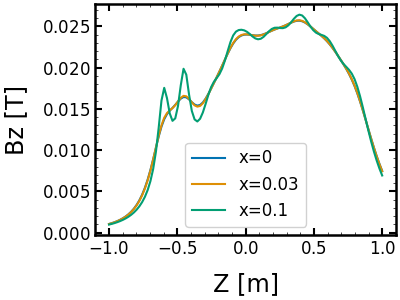

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt


config_path = os.path.expanduser("~/workplace/notebooks/SPHINX_arcsource_default.toml")


if not os.path.exists(config_path):
    print(f"【エラー】指定されたパスにファイルがありません: {config_path}")
else:
    print(f"ファイルを発見しました: {config_path}")
    
    # 3. 解析処理を実行
    mag = magcalc.MagNUMBER(config_path)

    z = np.linspace(-1, 1, 100)
    Bz1 = mag.get_B(x=0, z=np.linspace(-1, 1, 100), y=0).Bz.data.squeeze()  # type: ignore
    Bz2 = mag.get_B(x=0.03, z=np.linspace(-1, 1, 100), y=0).Bz.data.squeeze()  # type: ignore
    Bz3 = mag.get_B(x=0.1, z=np.linspace(-1, 1, 100), y=0).Bz.data.squeeze()  # type: ignore

    plt.figure()
    plt.plot(z, Bz1, label="x=0")
    plt.plot(z, Bz2, label="x=0.03")
    plt.plot(z, Bz3, label="x=0.1")
    plt.xlabel("Z [m]")
    plt.ylabel("Bz [T]")
    plt.legend()

In [3]:
mag.show()